# Sentinel-1 SAR Backscatter Change Experiment

This experiment evaluates whether Sentinel-1 radar backscatter changed around the monitored Witznitz study area between June 2021 and June 2024.

The experiment complements the Sentinel-2 NDVI analysis by measuring radar response rather than optical vegetation response.

## Acquisition controls

To improve temporal comparability, candidate acquisitions were selected using:

- Sentinel-1A
- IW acquisition mode
- GRD product
- VV polarization
- Descending orbit
- Relative orbit 95
- Similar June acquisition dates

Selected acquisitions:

- Before: 2021-06-13
- After: 2024-06-21

Raw Sentinel-1 GRD measurement data require radiometric calibration and geolocation processing before quantitative comparison. This experiment therefore uses Copernicus Data Space Ecosystem openEO processing rather than treating raw GRD amplitude values as analysis-ready backscatter.

In [2]:
import openeo

connection = openeo.connect(
    "https://openeo.dataspace.copernicus.eu"
)

capabilities = connection.capabilities()

print(capabilities)

In [3]:
collections = connection.list_collections()

sentinel1_collections = [
    collection
    for collection in collections
    if "SENTINEL1" in collection["id"].upper()
    or "SENTINEL-1" in collection["id"].upper()
]

for collection in sentinel1_collections:
    print(collection["id"])
    print(collection.get("title"))
    print()

SENTINEL1_GRD
Sentinel-1 SAR GRD: C-band Synthetic Aperture Radar Ground Range Detected.

SENTINEL1_GLOBAL_MOSAICS
Sentinel 1 Monthly Mosaics



In [5]:
s1_metadata = connection.describe_collection("SENTINEL1_GRD")

print(type(s1_metadata))
print(s1_metadata.keys())

<class 'openeo.internal.jupyter.VisualDict'>
dict_keys(['cube:dimensions', 'description', 'extent', 'id', 'keywords', 'license', 'links', 'mission', 'name', 'product_id', 'stac_extensions', 'stac_version', 'summaries', 'title'])


In [6]:
print("CUBE DIMENSIONS")
print(s1_metadata["cube:dimensions"])

print("\nSUMMARY KEYS")
print(s1_metadata["summaries"].keys())

CUBE DIMENSIONS
{'bands': {'type': 'bands', 'values': ['HH', 'HV', 'VH', 'VV']}, 't': {'extent': [None, None], 'type': 'temporal'}, 'x': {'axis': 'x', 'extent': [0, 0], 'reference_system': {'$schema': 'https://proj.org/schemas/v0.2/projjson.schema.json', 'area': 'World', 'bbox': {'east_longitude': 180, 'north_latitude': 90, 'south_latitude': -90, 'west_longitude': -180}, 'coordinate_system': {'axis': [{'abbreviation': 'Lat', 'direction': 'north', 'name': 'Geodetic latitude', 'unit': 'degree'}, {'abbreviation': 'Lon', 'direction': 'east', 'name': 'Geodetic longitude', 'unit': 'degree'}], 'subtype': 'ellipsoidal'}, 'datum': {'ellipsoid': {'inverse_flattening': 298.257223563, 'name': 'WGS 84', 'semi_major_axis': 6378137}, 'name': 'World Geodetic System 1984', 'type': 'GeodeticReferenceFrame'}, 'id': {'authority': 'OGC', 'code': 'Auto42001', 'version': '1.3'}, 'name': 'AUTO 42001 (Universal Transverse Mercator)', 'type': 'GeodeticCRS'}, 'step': 10, 'type': 'spatial'}, 'y': {'axis': 'y', 'e

In [7]:
keys_to_check = [
    "platform",
    "sar:instrument_mode",
    "sar:product_type",
    "sar:polarizations",
    "sat:orbit_state",
]

for key in keys_to_check:
    print(f"\n{key}")
    print(s1_metadata["summaries"].get(key))


platform
['sentinel-1a', 'sentinel-1b']

sar:instrument_mode
['SM', 'IW', 'EW', 'WV']

sar:product_type
['GRD']

sar:polarizations
['HH', 'HV', 'VH', 'VV']

sat:orbit_state
['ascending', 'descending']


In [8]:
load_collection = connection.describe_process("load_collection")

print(
    load_collection["parameters"]
)

[{'description': 'The collection id.', 'name': 'id', 'schema': {'pattern': '^[\\w\\-\\.~/]+$', 'subtype': 'collection-id', 'type': 'string'}}, {'description': 'Limits the data to load from the collection to the specified bounding box or polygons.\n\n* For raster data, the process loads the pixel into the data cube if the point at the pixel center intersects with the bounding box or any of the polygons (as defined in the Simple Features standard by the OGC).\n* For vector data, the process loads the geometry into the data cube if the geometry is fully *within* the bounding box or any of the polygons (as defined in the Simple Features standard by the OGC). Empty geometries may only be in the data cube if no spatial extent has been provided.\n\nThe GeoJSON can be one of the following feature types:\n\n* A `Polygon` or `MultiPolygon` geometry,\n* a `Feature` with a `Polygon` or `MultiPolygon` geometry, or\n* a `FeatureCollection` containing at least one `Feature` with `Polygon` or `MultiPo

In [9]:
connection.authenticate_oidc()

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=BTRB-ECVD 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.


<Connection to 'https://openeo.dataspace.copernicus.eu/openeo/1.2/' with OidcBearerAuth>

In [10]:
witznitz_bbox = {
    "west": 12.38886,
    "south": 51.12724,
    "east": 12.44886,
    "north": 51.18724,
}

s1_2021 = connection.load_collection(
    "SENTINEL1_GRD",
    spatial_extent=witznitz_bbox,
    temporal_extent=[
        "2021-06-13",
        "2021-06-14",
    ],
    bands=["VV"],
    properties={
        "platform": lambda value: value == "sentinel-1a",
        "sar:instrument_mode": lambda value: value == "IW",
        "sar:product_type": lambda value: value == "GRD",
        "sat:orbit_state": lambda value: value == "descending",
    },
)

print(s1_2021)

DataCube(<PGNode 'load_collection' at 0x23692acb160>)


In [11]:
sar_process = connection.describe_process(
    "sar_backscatter"
)

for parameter in sar_process["parameters"]:
    print("\nPARAMETER:", parameter["name"])
    print("Description:", parameter.get("description"))
    print("Default:", parameter.get("default", "NO DEFAULT"))
    print("Schema:", parameter.get("schema"))


PARAMETER: data
Description: The source data cube containing SAR input.
Default: NO DEFAULT
Schema: {'dimensions': [{'axis': ['x', 'y'], 'type': 'spatial'}, {'type': 'bands'}], 'subtype': 'datacube', 'type': 'object'}

PARAMETER: coefficient
Description: The radiometric correction coefficient.
On this backend, only the following option is available:

* `sigma0-ellipsoid`: ground area computed with ellipsoid earth model

Default: sigma0-ellipsoid
Schema: {'enum': ['sigma0-ellipsoid'], 'type': 'string'}

PARAMETER: elevation_model
Description: The digital elevation model to use. Set to `null` (the default) to allow the back-end to choose, which will improve portability, but reduce reproducibility.
Default: None
Schema: [{'subtype': 'collection-id', 'type': 'string'}, {'type': 'null'}]

PARAMETER: mask
Description: If set to `true`, a data mask is added to the bands with the name `mask`. It indicates which values are valid (1), invalid (0) or contain no-data (null).
Default: False
Schema

In [12]:
s1_2021_sigma0 = s1_2021.sar_backscatter(
    coefficient="sigma0-ellipsoid",
    noise_removal=True,
)

print(s1_2021_sigma0)

DataCube(<PGNode 'sar_backscatter' at 0x23692ac8230>)


In [13]:
s1_2024 = connection.load_collection(
    "SENTINEL1_GRD",
    spatial_extent=witznitz_bbox,
    temporal_extent=[
        "2024-06-21",
        "2024-06-22",
    ],
    bands=["VV"],
    properties={
        "platform": lambda value: value == "sentinel-1a",
        "sar:instrument_mode": lambda value: value == "IW",
        "sar:product_type": lambda value: value == "GRD",
        "sat:orbit_state": lambda value: value == "descending",
    },
)

s1_2024_sigma0 = s1_2024.sar_backscatter(
    coefficient="sigma0-ellipsoid",
    noise_removal=True,
)

print(s1_2024_sigma0)

DataCube(<PGNode 'sar_backscatter' at 0x23692930e60>)


In [14]:
resample_process = connection.describe_process(
    "resample_spatial"
)

for parameter in resample_process["parameters"]:
    print("\nPARAMETER:", parameter["name"])
    print("Description:", parameter.get("description"))
    print("Default:", parameter.get("default", "NO DEFAULT"))
    print("Schema:", parameter.get("schema"))


PARAMETER: data
Description: A raster data cube.
Default: NO DEFAULT
Schema: {'dimensions': [{'axis': ['x', 'y'], 'type': 'spatial'}], 'subtype': 'datacube', 'type': 'object'}

PARAMETER: resolution
Description: Resamples the data cube to the target resolution, which can be specified either as separate values for x and y or as a single value for both axes. Specified in the units of the target projection. Doesn't change the resolution by default (`0`).
Default: 0
Schema: [{'description': 'A single number used as the resolution for both x and y.', 'minimum': 0, 'type': 'number'}, {'description': 'A two-element array to specify separate resolutions for x (first element) and y (second element).', 'items': {'minimum': 0, 'type': 'number'}, 'maxItems': 2, 'minItems': 2, 'type': 'array'}]

PARAMETER: projection
Description: Warps the data cube to the target projection, specified as as [EPSG code](http://www.epsg-registry.org/) or [WKT2 CRS string](http://docs.opengeospatial.org/is/18-010r7/1

In [15]:
s1_2021_ready = s1_2021_sigma0.resample_spatial(
    resolution=10,
    projection=32633,
    method="bilinear",
)

s1_2024_ready = s1_2024_sigma0.resample_spatial(
    resolution=10,
    projection=32633,
    method="bilinear",
)

print(s1_2021_ready)
print(s1_2024_ready)

DataCube(<PGNode 'resample_spatial' at 0x236929309b0>)
DataCube(<PGNode 'resample_spatial' at 0x23692930a50>)


In [16]:
job_2021 = s1_2021_ready.create_job(
    out_format="GTiff",
    title="IRIS-Lite Sentinel-1 Witznitz 2021 VV Sigma0",
)

print(job_2021)

<BatchJob job_id='j-2610070117414f4590715ce7777026d3'>


In [17]:
job_2021.start_and_wait()

0:00:00 Job 'j-2610070117414f4590715ce7777026d3': send 'start'
0:00:02 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:00:07 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:00:13 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:00:21 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:00:32 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:00:44 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:01:00 Job 'j-2610070117414f4590715ce7777026d3': queued (progress 0%)
0:01:19 Job 'j-2610070117414f4590715ce7777026d3': finished (progress 100%)


<BatchJob job_id='j-2610070117414f4590715ce7777026d3'>

In [19]:
results_2021 = job_2021.get_results()

downloaded_2021 = results_2021.download_files(
    target="data/processed/sentinel1/2021"
)

print(downloaded_2021)

[WindowsPath('data/processed/sentinel1/2021/openEO_2021-06-13Z.tif'), WindowsPath('data/processed/sentinel1/2021/job-results.json')]


In [22]:
import rasterio
import numpy as np

s1_2021_path = "../data/processed/sentinel1/2021/openEO_2021-06-13Z.tif"

with rasterio.open(s1_2021_path) as src:
    s1_2021_data = src.read(1)

    print("Driver:", src.driver)
    print("Bands:", src.count)
    print("Shape:", (src.height, src.width))
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Dtype:", src.dtypes[0])
    print("Nodata:", src.nodata)

    valid = s1_2021_data[np.isfinite(s1_2021_data)]

    print("Valid pixels:", valid.size)
    print("Minimum:", valid.min())
    print("Maximum:", valid.max())
    print("Mean:", valid.mean())
    print("Median:", np.median(valid))

Driver: GTiff
Bands: 1
Shape: (683, 444)
CRS: EPSG:32633
Transform: | 10.00, 0.00, 317290.00|
| 0.00,-10.00, 5673890.00|
| 0.00, 0.00, 1.00|
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=317290.0, bottom=5667060.0, right=321730.0, top=5673890.0)
Dtype: float64
Nodata: 0.0
Valid pixels: 303252
Minimum: 7.431476205965737e-06
Maximum: 83.8591537475586
Mean: 0.07808713968702706
Median: 0.047665541991591454


In [21]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("Expected file exists:", Path("data/processed/sentinel1/2021/openEO_2021-06-13Z.tif").exists())

Working directory: c:\Users\joyal\Projects\iris-lite\notebooks
Expected file exists: True


In [23]:
job_2024 = s1_2024_ready.create_job(
    out_format="GTiff",
    title="IRIS-Lite Sentinel-1 Witznitz 2024 VV Sigma0",
)

print(job_2024)

<BatchJob job_id='j-26100701282043ae8ab2b482c9a9edfa'>


In [24]:
job_2024.start_and_wait()

0:00:00 Job 'j-26100701282043ae8ab2b482c9a9edfa': send 'start'
0:00:01 Job 'j-26100701282043ae8ab2b482c9a9edfa': created (progress 0%)
0:00:07 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:00:13 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:00:21 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:00:31 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:00:44 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:00:59 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:01:19 Job 'j-26100701282043ae8ab2b482c9a9edfa': queued (progress 0%)
0:01:43 Job 'j-26100701282043ae8ab2b482c9a9edfa': finished (progress 100%)


<BatchJob job_id='j-26100701282043ae8ab2b482c9a9edfa'>

In [25]:
results_2024 = job_2024.get_results()

downloaded_2024 = results_2024.download_files(
    target="../data/processed/sentinel1/2024"
)

print(downloaded_2024)

[WindowsPath('../data/processed/sentinel1/2024/openEO_2024-06-21Z.tif'), WindowsPath('../data/processed/sentinel1/2024/job-results.json')]


In [26]:
s1_2021_path = "../data/processed/sentinel1/2021/openEO_2021-06-13Z.tif"
s1_2024_path = "../data/processed/sentinel1/2024/openEO_2024-06-21Z.tif"

with rasterio.open(s1_2021_path) as src_2021, rasterio.open(s1_2024_path) as src_2024:

    print("2021")
    print("Shape:", (src_2021.height, src_2021.width))
    print("CRS:", src_2021.crs)
    print("Resolution:", src_2021.res)
    print("Transform:", src_2021.transform)
    print("Bounds:", src_2021.bounds)

    print("\n2024")
    print("Shape:", (src_2024.height, src_2024.width))
    print("CRS:", src_2024.crs)
    print("Resolution:", src_2024.res)
    print("Transform:", src_2024.transform)
    print("Bounds:", src_2024.bounds)

    print("\nGRID CHECKS")
    print("Same shape:", src_2021.shape == src_2024.shape)
    print("Same CRS:", src_2021.crs == src_2024.crs)
    print("Same resolution:", src_2021.res == src_2024.res)
    print("Same transform:", src_2021.transform == src_2024.transform)
    print("Same bounds:", src_2021.bounds == src_2024.bounds)

2021
Shape: (683, 444)
CRS: EPSG:32633
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 317290.00|
| 0.00,-10.00, 5673890.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=317290.0, bottom=5667060.0, right=321730.0, top=5673890.0)

2024
Shape: (683, 444)
CRS: EPSG:32633
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 317290.00|
| 0.00,-10.00, 5673890.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=317290.0, bottom=5667060.0, right=321730.0, top=5673890.0)

GRID CHECKS
Same shape: True
Same CRS: True
Same resolution: True
Same transform: True
Same bounds: True


In [27]:
with rasterio.open(s1_2021_path) as src_2021, rasterio.open(s1_2024_path) as src_2024:
    vv_2021 = src_2021.read(1).astype("float64")
    vv_2024 = src_2024.read(1).astype("float64")

    nodata_2021 = src_2021.nodata
    nodata_2024 = src_2024.nodata

vv_2021[vv_2021 == nodata_2021] = np.nan
vv_2024[vv_2024 == nodata_2024] = np.nan

print("2021")
print("Valid pixels:", np.isfinite(vv_2021).sum())
print("Min:", np.nanmin(vv_2021))
print("Max:", np.nanmax(vv_2021))
print("Mean:", np.nanmean(vv_2021))
print("Median:", np.nanmedian(vv_2021))

print("\n2024")
print("Valid pixels:", np.isfinite(vv_2024).sum())
print("Min:", np.nanmin(vv_2024))
print("Max:", np.nanmax(vv_2024))
print("Mean:", np.nanmean(vv_2024))
print("Median:", np.nanmedian(vv_2024))

print("\nBoth years valid:", np.sum(
    np.isfinite(vv_2021) & np.isfinite(vv_2024)
))

2021
Valid pixels: 303252
Min: 7.431476205965737e-06
Max: 83.8591537475586
Mean: 0.07808713968702706
Median: 0.047665541991591454

2024
Valid pixels: 303251
Min: 6.3970283008529805e-06
Max: 71.91746520996094
Mean: 0.08858249286741213
Median: 0.06337552517652512

Both years valid: 303251


In [28]:
valid_both = (
    np.isfinite(vv_2021) &
    np.isfinite(vv_2024) &
    (vv_2021 > 0) &
    (vv_2024 > 0)
)

vv_2021_db = np.full(vv_2021.shape, np.nan, dtype="float64")
vv_2024_db = np.full(vv_2024.shape, np.nan, dtype="float64")

vv_2021_db[valid_both] = 10 * np.log10(vv_2021[valid_both])
vv_2024_db[valid_both] = 10 * np.log10(vv_2024[valid_both])

print("2021 median VV:", np.nanmedian(vv_2021_db), "dB")
print("2024 median VV:", np.nanmedian(vv_2024_db), "dB")

2021 median VV: -13.217945649050737 dB
2024 median VV: -11.980784287580654 dB


In [29]:
vv_change_db = vv_2024_db - vv_2021_db

print("VV CHANGE: 2024 - 2021")
print("Valid pixels:", np.isfinite(vv_change_db).sum())
print("Mean change:", np.nanmean(vv_change_db), "dB")
print("Median change:", np.nanmedian(vv_change_db), "dB")
print("Minimum change:", np.nanmin(vv_change_db), "dB")
print("Maximum change:", np.nanmax(vv_change_db), "dB")

print(
    "Fraction increased:",
    np.mean(vv_change_db[valid_both] > 0)
)

print(
    "Fraction decreased:",
    np.mean(vv_change_db[valid_both] < 0)
)

VV CHANGE: 2024 - 2021
Valid pixels: 303251
Mean change: 0.4377397048630678 dB
Median change: 0.4756414550268566 dB
Minimum change: -30.849487933425117 dB
Maximum change: 28.497321812277985 dB
Fraction increased: 0.5546560440031525
Fraction decreased: 0.4453439559968475


In [30]:
s2_change_path = "../outputs/ndvi_change_2021_2024_cog.tif"

with rasterio.open(s2_change_path) as s2:
    print("SENTINEL-2 CHANGE RASTER")
    print("Shape:", s2.shape)
    print("CRS:", s2.crs)
    print("Resolution:", s2.res)
    print("Transform:", s2.transform)
    print("Bounds:", s2.bounds)

SENTINEL-2 CHANGE RASTER
Shape: (100, 100)
CRS: EPSG:32633
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 319000.00|
| 0.00,-10.00, 5670980.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=319000.0, bottom=5669980.0, right=320000.0, top=5670980.0)


In [31]:
from rasterio.windows import from_bounds

with rasterio.open(s2_change_path) as s2:
    analysis_bounds = s2.bounds

with rasterio.open(s1_2021_path) as src_2021:
    window = from_bounds(
        *analysis_bounds,
        transform=src_2021.transform
    )

    vv_2021_aoi = src_2021.read(1, window=window).astype("float64")

with rasterio.open(s1_2024_path) as src_2024:
    vv_2024_aoi = src_2024.read(1, window=window).astype("float64")

print("Window:", window)
print("2021 AOI shape:", vv_2021_aoi.shape)
print("2024 AOI shape:", vv_2024_aoi.shape)

Window: Window(col_off=np.float64(171.0), row_off=np.float64(291.0), width=np.float64(100.0), height=np.float64(100.0))
2021 AOI shape: (100, 100)
2024 AOI shape: (100, 100)


In [32]:
# Treat openEO nodata value (0) as missing
vv_2021_aoi[vv_2021_aoi == 0] = np.nan
vv_2024_aoi[vv_2024_aoi == 0] = np.nan

# Pixels must be valid and positive in both years for log10 conversion
valid_aoi = (
    np.isfinite(vv_2021_aoi) &
    np.isfinite(vv_2024_aoi) &
    (vv_2021_aoi > 0) &
    (vv_2024_aoi > 0)
)

# Convert linear sigma0 to dB
vv_2021_aoi_db = np.full(vv_2021_aoi.shape, np.nan)
vv_2024_aoi_db = np.full(vv_2024_aoi.shape, np.nan)

vv_2021_aoi_db[valid_aoi] = 10 * np.log10(vv_2021_aoi[valid_aoi])
vv_2024_aoi_db[valid_aoi] = 10 * np.log10(vv_2024_aoi[valid_aoi])

# Change = after - before
vv_change_aoi_db = vv_2024_aoi_db - vv_2021_aoi_db

print("COMMON 1 KM² AOI")
print("Valid pixels:", np.sum(valid_aoi))
print("2021 median VV:", np.nanmedian(vv_2021_aoi_db), "dB")
print("2024 median VV:", np.nanmedian(vv_2024_aoi_db), "dB")
print("Mean change:", np.nanmean(vv_change_aoi_db), "dB")
print("Median change:", np.nanmedian(vv_change_aoi_db), "dB")
print("Fraction increased:", np.mean(vv_change_aoi_db[valid_aoi] > 0))
print("Fraction decreased:", np.mean(vv_change_aoi_db[valid_aoi] < 0))

COMMON 1 KM² AOI
Valid pixels: 10000
2021 median VV: -14.008333946189913 dB
2024 median VV: -13.978035116289583 dB
Mean change: -0.34908190912336684 dB
Median change: -0.1725591598994498 dB
Fraction increased: 0.4834
Fraction decreased: 0.5166


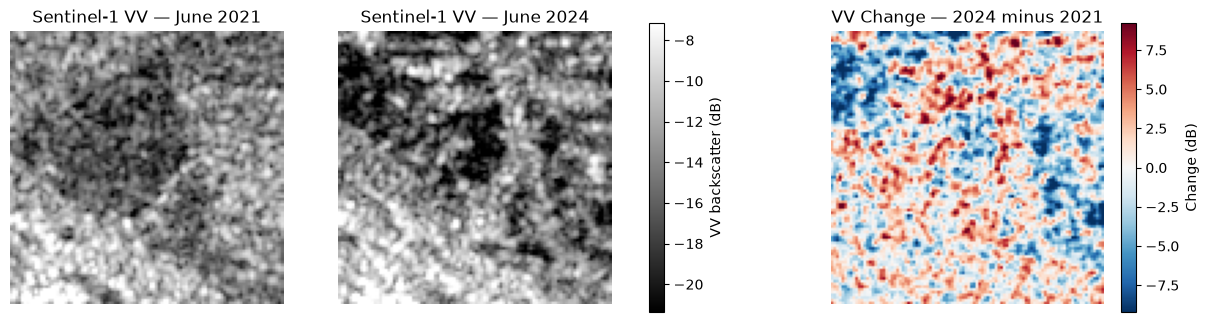

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use the same display range for both years
all_db = np.concatenate([
    vv_2021_aoi_db[np.isfinite(vv_2021_aoi_db)],
    vv_2024_aoi_db[np.isfinite(vv_2024_aoi_db)]
])

vmin = np.percentile(all_db, 2)
vmax = np.percentile(all_db, 98)

im1 = axes[0].imshow(
    vv_2021_aoi_db,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
axes[0].set_title("Sentinel-1 VV — June 2021")
axes[0].axis("off")

im2 = axes[1].imshow(
    vv_2024_aoi_db,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
axes[1].set_title("Sentinel-1 VV — June 2024")
axes[1].axis("off")

# Symmetric change scale so increases/decreases are visually comparable
change_limit = np.nanpercentile(np.abs(vv_change_aoi_db), 98)

im3 = axes[2].imshow(
    vv_change_aoi_db,
    cmap="RdBu_r",
    vmin=-change_limit,
    vmax=change_limit
)
axes[2].set_title("VV Change — 2024 minus 2021")
axes[2].axis("off")

fig.colorbar(im1, ax=axes[:2], label="VV backscatter (dB)", shrink=0.75)
fig.colorbar(im3, ax=axes[2], label="Change (dB)", shrink=0.75)

plt.show()

In [34]:
with rasterio.open(s2_change_path) as src:
    ndvi_change = src.read(1).astype("float64")

    if src.nodata is not None:
        ndvi_change[ndvi_change == src.nodata] = np.nan

print("NDVI shape:", ndvi_change.shape)
print("S1 change shape:", vv_change_aoi_db.shape)

print(
    "Both valid:",
    np.sum(
        np.isfinite(ndvi_change) &
        np.isfinite(vv_change_aoi_db)
    )
)

NDVI shape: (100, 100)
S1 change shape: (100, 100)
Both valid: 10000


In [35]:
from rasterio.windows import transform as window_transform

with rasterio.open(s1_2021_path) as s1, rasterio.open(s2_change_path) as s2:
    s1_aoi_transform = window_transform(window, s1.transform)

    print("S1 cropped transform:")
    print(s1_aoi_transform)

    print("\nS2 transform:")
    print(s2.transform)

    print("\nGRID CHECK")
    print("Same CRS:", s1.crs == s2.crs)
    print("Same resolution:", s1.res == s2.res)
    print("Same shape:", vv_change_aoi_db.shape == s2.shape)
    print("Same transform:", s1_aoi_transform == s2.transform)

S1 cropped transform:
| 10.00, 0.00, 319000.00|
| 0.00,-10.00, 5670980.00|
| 0.00, 0.00, 1.00|

S2 transform:
| 10.00, 0.00, 319000.00|
| 0.00,-10.00, 5670980.00|
| 0.00, 0.00, 1.00|

GRID CHECK
Same CRS: True
Same resolution: True
Same shape: True
Same transform: True


In [36]:
cross_valid = (
    np.isfinite(ndvi_change) &
    np.isfinite(vv_change_aoi_db)
)

ndvi_values = ndvi_change[cross_valid]
vv_values = vv_change_aoi_db[cross_valid]

correlation = np.corrcoef(ndvi_values, vv_values)[0, 1]

print("Cross-sensor comparison")
print("Pixels compared:", len(ndvi_values))
print("Pearson correlation:", correlation)

print("\nNDVI change")
print("Mean:", np.mean(ndvi_values))
print("Median:", np.median(ndvi_values))

print("\nVV change")
print("Mean:", np.mean(vv_values), "dB")
print("Median:", np.median(vv_values), "dB")

Cross-sensor comparison
Pixels compared: 10000
Pearson correlation: 0.30519928625759807

NDVI change
Mean: -0.23576859619090004
Median: -0.1523325964808464

VV change
Mean: -0.34908190912336684 dB
Median: -0.1725591598994498 dB


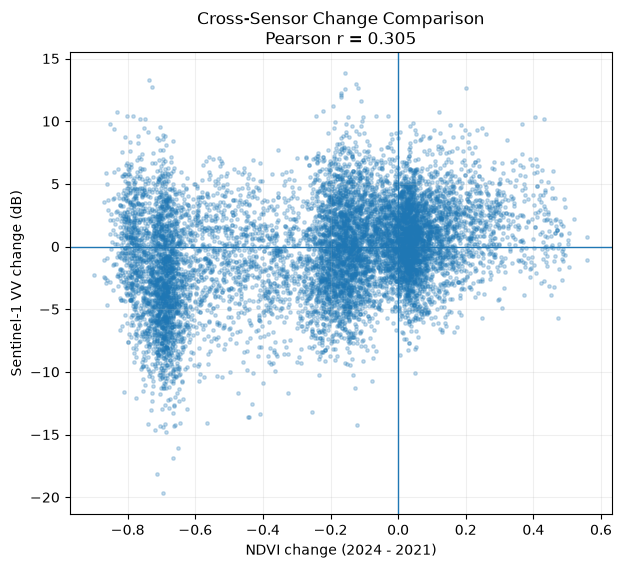

In [37]:
plt.figure(figsize=(7, 6))

plt.scatter(
    ndvi_values,
    vv_values,
    s=6,
    alpha=0.25
)

plt.axvline(0, linewidth=1)
plt.axhline(0, linewidth=1)

plt.xlabel("NDVI change (2024 - 2021)")
plt.ylabel("Sentinel-1 VV change (dB)")
plt.title(
    f"Cross-Sensor Change Comparison\n"
    f"Pearson r = {correlation:.3f}"
)

plt.grid(alpha=0.2)
plt.show()

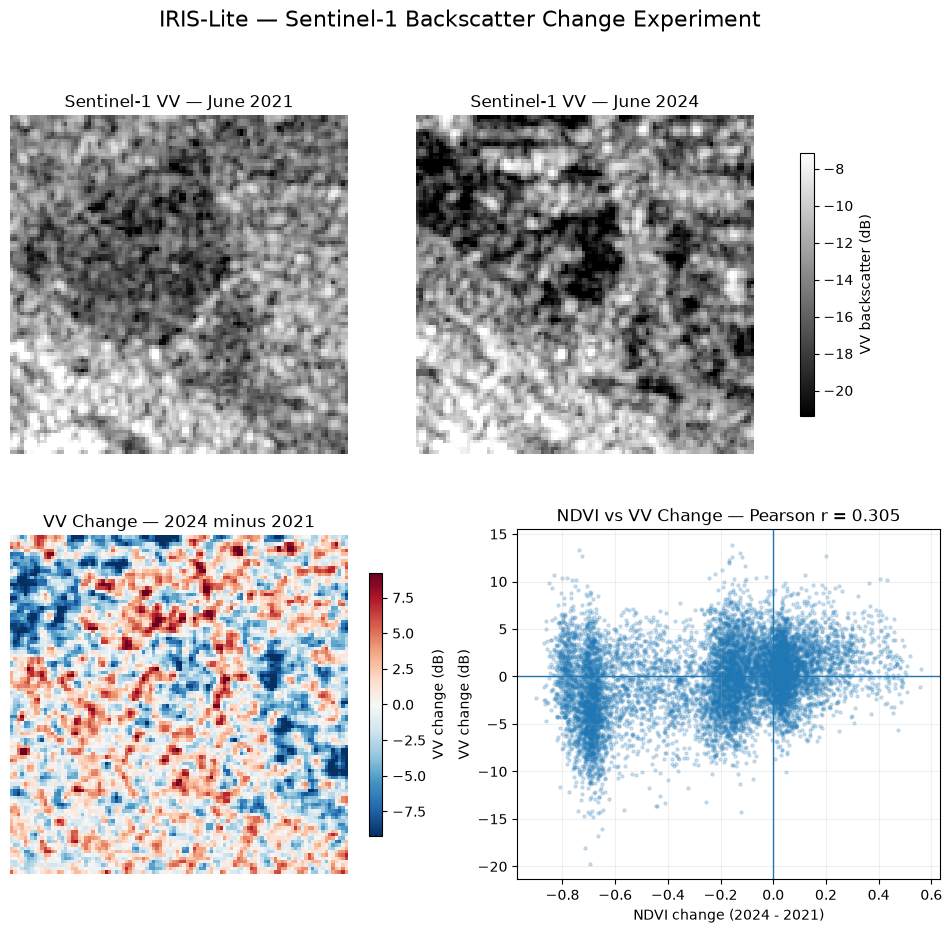

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Shared display range for 2021 and 2024 VV
all_db = np.concatenate([
    vv_2021_aoi_db[np.isfinite(vv_2021_aoi_db)],
    vv_2024_aoi_db[np.isfinite(vv_2024_aoi_db)]
])

vmin = np.percentile(all_db, 2)
vmax = np.percentile(all_db, 98)

# 2021 VV
im1 = axes[0, 0].imshow(
    vv_2021_aoi_db,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
axes[0, 0].set_title("Sentinel-1 VV — June 2021")
axes[0, 0].axis("off")

# 2024 VV
axes[0, 1].imshow(
    vv_2024_aoi_db,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)
axes[0, 1].set_title("Sentinel-1 VV — June 2024")
axes[0, 1].axis("off")

# VV change
change_limit = np.nanpercentile(np.abs(vv_change_aoi_db), 98)

im_change = axes[1, 0].imshow(
    vv_change_aoi_db,
    cmap="RdBu_r",
    vmin=-change_limit,
    vmax=change_limit
)
axes[1, 0].set_title("VV Change — 2024 minus 2021")
axes[1, 0].axis("off")

# Cross-sensor comparison
axes[1, 1].scatter(
    ndvi_values,
    vv_values,
    s=5,
    alpha=0.20
)

axes[1, 1].axvline(0, linewidth=1)
axes[1, 1].axhline(0, linewidth=1)

axes[1, 1].set_xlabel("NDVI change (2024 - 2021)")
axes[1, 1].set_ylabel("VV change (dB)")
axes[1, 1].set_title(
    f"NDVI vs VV Change — Pearson r = {correlation:.3f}"
)
axes[1, 1].grid(alpha=0.2)

# Colorbars
fig.colorbar(
    im1,
    ax=[axes[0, 0], axes[0, 1]],
    label="VV backscatter (dB)",
    shrink=0.75
)

fig.colorbar(
    im_change,
    ax=axes[1, 0],
    label="VV change (dB)",
    shrink=0.75
)

fig.suptitle(
    "IRIS-Lite — Sentinel-1 Backscatter Change Experiment",
    fontsize=16
)

plt.savefig(
    "../outputs/sentinel1/sentinel1_change_2021_2024.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()